# Dominant eigenvalue and frequency surfaces

Run the cells in order with the `Results` directory inside your working directory, or set `BASE_DIR` below.

Use rho_e = 0.0 for reproducing figure 5b and rho_e = 0.6 for figure 5c

Requirements: NumPy, SciPy, Matplotlib, and pandas (`%pip install numpy scipy matplotlib pandas` if needed).

The supplied assumption is retained: column 1 contains the eigenvalue real part and **column 2 already contains frequency in Hz**; its absolute value is used, without a $2\pi$ conversion. Reflection symmetry is assumed as in the original. The sampled quadrant has nonnegative coordinates.

`viridis` replaces the external `slanCM(72,100)` palette. SciPy's cubic interpolant is not numerically identical to MATLAB's. Nearest-neighbour interpolation is masked outside the data convex hull to retain MATLAB `griddata`'s domain behavior. No result data were supplied, so the notebook has not been run on your measurements.

In [1]:
from pathlib import Path
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.io import loadmat
from scipy.interpolate import griddata
from IPython.display import display

BASE_DIR = Path.cwd()

g = 3.30
rho_ee = 0.6
rho_ii = 0.0
rho_ei = 0.0
rho_ie = 0.0
vel = 300
nu_ext = 2000.00

foldername = BASE_DIR / (
    f"Results/rhoEE{rho_ee:.1f}_rhoII{rho_ii:.1f}_rhoIE{rho_ie:.1f}_rhoEI{rho_ei:.1f}_"
    f"g{g:.2f}_nuext{nu_ext:.2f}_v{vel:g}"
)

N_pt_u = 21
Nx = N_pt_u
N_pt_v = 21
List_ky = np.linspace(0, 1.5, N_pt_v)
List_kx = np.linspace(0, 1.5, N_pt_u)
CMAP = plt.get_cmap("viridis", 100)
print("Data folder:", foldername.resolve())

Data folder: /Users/ludovica/Documents/Documents_MAC/Duke/Brian_simulations/Paper_figures_simulations/GitHub_clean/theory/Fig5_python/Results/rhoEE0.0_rhoII0.0_rhoIE0.0_rhoEI0.0_g3.30_nuext2000.00_v300


## Load all eigenvalue branches

In [2]:
all_param_kx = []
all_param_ky = []
all_minima_real = []
all_minima_frequency = []

for kx in List_kx:
    
    myname = (f"Stability_rhoEE{rho_ee:.1f}_rhoII{rho_ii:.1f}_rhoIE{rho_ie:.1f}_rhoEI{rho_ei:.1f}_"f"nu_ext{nu_ext:.2f}_g{g:.2f}_"f"v{vel:.1f}_kx{kx:.2f}.mat")
    filepath = foldername / myname
    if not filepath.is_file():
        raise FileNotFoundError(f"Missing data file: {filepath.resolve()}")
    # Keep two-dimensional cell contents, including single-row minima.
    ld = loadmat(filepath, squeeze_me=False)
    if "local_minima_all" not in ld:
        raise KeyError(f"local_minima_all is missing from {filepath}")
    cells = ld["local_minima_all"]
    if cells.dtype != object:
        raise ValueError(f"Expected a MATLAB cell array in {filepath}")
    cells = cells.ravel(order="F")  # MATLAB linear indexing
    if cells.size < N_pt_v:
        raise ValueError(f"Expected at least {N_pt_v} cells in {filepath}; found {cells.size}")
    for i, ky in enumerate(List_ky):
        min_h = np.asarray(cells[i], dtype=float)
        # Empty cells contain no roots and contribute no rows.
        if min_h.size == 0:
            continue
        if min_h.ndim != 2 or min_h.shape[1] < 2:
            raise ValueError(
                f"local_minima_all{{{i+1}}} in {filepath} has fewer than two "
                "columns or is not a matrix. The frequency column must be identified."
            )
        nr_minima = min_h.shape[0]
        all_param_kx.extend(np.full(nr_minima, kx))
        all_param_ky.extend(np.full(nr_minima, ky))
        all_minima_real.extend(min_h[:, 0])
        all_minima_frequency.extend(np.abs(min_h[:, 1]))

all_param_kx = np.asarray(all_param_kx)
all_param_ky = np.asarray(all_param_ky)
all_minima_real = np.asarray(all_minima_real)
all_minima_frequency = np.asarray(all_minima_frequency)

## Reconstruct the four quadrants and select the dominant branch

In [3]:
all_param_kx_LU = all_param_kx.copy()
all_param_ky_LU = all_param_ky.copy()
all_minima_real_LU = all_minima_real.copy()
all_minima_frequency_LU = all_minima_frequency.copy()
all_param_kx = np.concatenate([all_param_kx_LU, -all_param_kx_LU,
                               all_param_kx_LU, -all_param_kx_LU])
all_param_ky = np.concatenate([all_param_ky_LU, all_param_ky_LU,
                               -all_param_ky_LU, -all_param_ky_LU])
all_minima_real = np.tile(all_minima_real_LU, 4)
all_minima_frequency = np.tile(all_minima_frequency_LU, 4)

valid_idx = (np.isfinite(all_param_kx) & np.isfinite(all_param_ky)
             & np.isfinite(all_minima_real) & np.isfinite(all_minima_frequency))
u_valid = all_param_kx[valid_idx]
v_valid = all_param_ky[valid_idx]
Re_valid = all_minima_real[valid_idx]
frequency_valid = all_minima_frequency[valid_idx]
if Re_valid.size == 0:
    raise ValueError("No finite eigenvalue rows were found.")
uv_unique, group_id = np.unique(np.column_stack([u_valid, v_valid]),
                                axis=0, return_inverse=True)
u_unique, v_unique = uv_unique.T
number_of_wavevectors = len(uv_unique)
Re_lambda_dominant = np.full(number_of_wavevectors, np.nan)
frequency_dominant = np.full(number_of_wavevectors, np.nan)
for iGroup in range(number_of_wavevectors):
    rows_here = np.flatnonzero(group_id == iGroup)
    # argmax takes the first row in a tie, as in MATLAB max.
    dominant_row = rows_here[np.argmax(Re_valid[rows_here])]
    Re_lambda_dominant[iGroup] = Re_valid[dominant_row]
    frequency_dominant[iGroup] = frequency_valid[dominant_row]

## Raw origin value and global maximum

In [4]:
origin_tolerance = 1e-12
origin_idx = ((np.abs(u_unique) <= origin_tolerance)
              & (np.abs(v_unique) <= origin_tolerance))
if np.any(origin_idx):
    Re_lambda_00 = np.max(Re_lambda_dominant[origin_idx])
    print(f"\nDominant Re lambda(0,0) = {Re_lambda_00:.12g}")
else:
    warnings.warn("No raw data point was found at (u,v) = (0,0). "
                  "Re lambda(0,0) was not estimated by interpolation.")
    Re_lambda_00 = np.nan
max_index = np.argmax(Re_lambda_dominant)
max_Re_lambda = Re_lambda_dominant[max_index]
u_at_global_max = u_unique[max_index]
v_at_global_max = v_unique[max_index]
print(f"Maximum dominant Re lambda = {max_Re_lambda:.12g}")
print(f"Location of maximum: u = {u_at_global_max:.12g}, v = {v_at_global_max:.12g}")
if np.isfinite(Re_lambda_00):
    print(f"Growth-rate advantage over k = 0: {max_Re_lambda - Re_lambda_00:.12g}")


Dominant Re lambda(0,0) = 0.376376873724
Maximum dominant Re lambda = 4.25026003033
Location of maximum: u = -0, v = -0.975
Growth-rate advantage over k = 0: 3.8738831566


## Interpolate and plot the three surfaces
Cubic interpolation is used only for the growth-rate visualization. Linear interpolation for the difference avoids cubic overshoot. Nearest-neighbour interpolation preserves abrupt frequency branch boundaries.

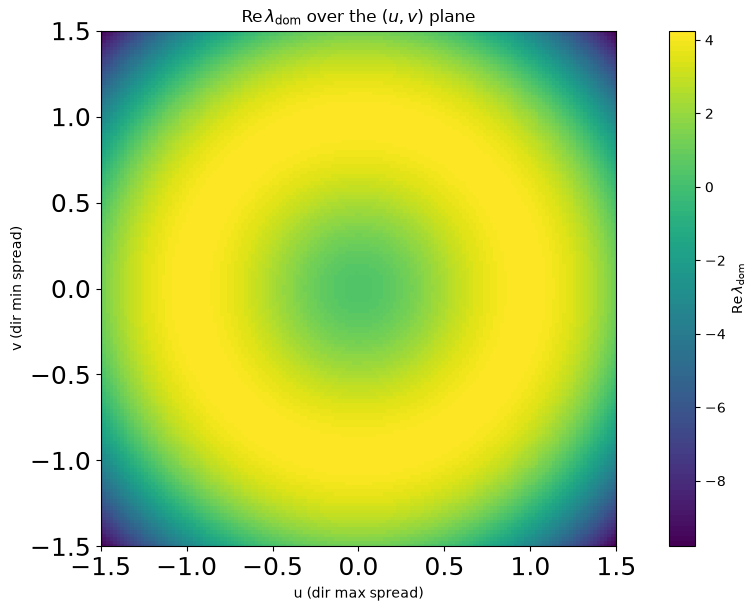

In [6]:
nGrid = 200
xq = np.linspace(-2, 2, nGrid)
yq = np.linspace(-2, 2, nGrid)
Xq, Yq = np.meshgrid(xq, yq)
Zq = griddata(uv_unique, Re_lambda_dominant, (Xq, Yq), method="cubic")
Zq_linear = griddata(uv_unique, Re_lambda_dominant, (Xq, Yq), method="linear")
Delta_lambda_q = Zq_linear - max_Re_lambda
Frequency_q = griddata(uv_unique, frequency_dominant, (Xq, Yq), method="nearest")
Frequency_q[~np.isfinite(Zq_linear)] = np.nan

cols = (xq >= -1.5) & (xq <= 1.5)
rows = (yq >= -1.5) & (yq <= 1.5)

def plot_surface(values, title, colorbar_label, vmin=None, vmax=None, filename=None):
    fig, ax = plt.subplots(figsize=(8, 6), constrained_layout=True)
    # Match imagesc: xq/yq describe pixel centers.
    dx, dy = xq[1] - xq[0], yq[1] - yq[0]
    im = ax.imshow(values, origin="lower", interpolation="nearest",
                   extent=[xq[0]-dx/2, xq[-1]+dx/2, yq[0]-dy/2, yq[-1]+dy/2],
                   cmap=CMAP, vmin=vmin, vmax=vmax)
    ax.set(xlim=(-1.5, 1.5), ylim=(-1.5, 1.5),
           xlabel="u (dir max spread)", ylabel="v (dir min spread)", title=title)
    ax.set_aspect("equal")
    ax.tick_params(labelsize=18)
    cb = fig.colorbar(im, ax=ax)
    cb.set_label(colorbar_label)

    if filename is not None:
        fig.savefig(filename, format="svg", bbox_inches="tight")
        
    plt.show()
    return fig, ax

Zclip = Zq[np.ix_(rows, cols)]
cmin, cmax = np.nanmin(Zclip), np.nanmax(Zclip)
 
tag = (f"rhoEE{rho_ee:.1f}_rhoII{rho_ii:.1f}_rhoIE{rho_ie:.1f}_rhoEI{rho_ei:.1f}_"f"g{g:.2f}_nuext{nu_ext:.2f}_v{vel:g}")


fig_growth, ax_growth = plot_surface(
    Zq, r"$\mathrm{Re}\,\lambda_{\mathrm{dom}}$ over the $(u,v)$ plane",
    r"$\mathrm{Re}\,\lambda_{\mathrm{dom}}$",
    cmin, cmax,
    filename=f"dominant_eigenvalue_{tag}.svg",
)


Frequency_clip = Frequency_q[np.ix_(rows, cols)]
frequency_min, frequency_max = np.nanmin(Frequency_clip), np.nanmax(Frequency_clip)
frequency_limits = ((frequency_min, frequency_max)
                    if np.isfinite(frequency_min) and np.isfinite(frequency_max)
                    and frequency_max > frequency_min else (None, None))



 

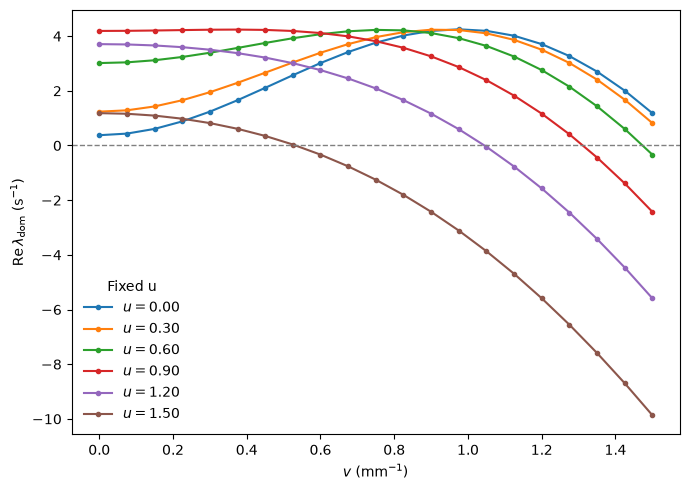

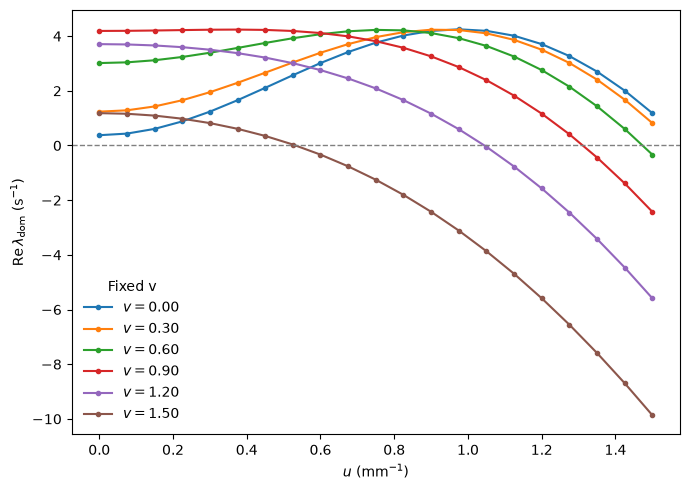

In [9]:

# Number of curves per figure
n_curves = 6

# Select fixed u and v values from the sampled grid
u_slices = List_kx[
    np.unique(np.linspace(0, len(List_kx)-1, n_curves, dtype=int))
]
v_slices = List_ky[
    np.unique(np.linspace(0, len(List_ky)-1, n_curves, dtype=int))
]

# ------------------------------------------------------------
# Figure 1: Re(lambda) vs v for different fixed u
# ------------------------------------------------------------
fig, ax = plt.subplots(figsize=(7, 5))

for u0 in u_slices:
    mask = (
        np.isclose(u_unique, u0, rtol=0, atol=1e-10)
        & (v_unique >= 0)
        & np.isfinite(Re_lambda_dominant)
    )

    order = np.argsort(v_unique[mask])

    ax.plot(
        v_unique[mask][order],
        Re_lambda_dominant[mask][order],
        '-o', markersize=3, lw=1.5,
        label=fr'$u={u0:.2f}$'
    )

ax.axhline(0, color='gray', ls='--', lw=1)
ax.set_xlabel(r'$v$ (mm$^{-1}$)')
ax.set_ylabel(r'$\mathrm{Re}\,\lambda_{\mathrm{dom}}$ (s$^{-1}$)')
ax.legend(frameon=False, title='Fixed u')
fig.tight_layout()
plt.show()


# ------------------------------------------------------------
# Figure 2: Re(lambda) vs u for different fixed v
# ------------------------------------------------------------
fig, ax = plt.subplots(figsize=(7, 5))

for v0 in v_slices:
    mask = (
        np.isclose(v_unique, v0, rtol=0, atol=1e-10)
        & (u_unique >= 0)
        & np.isfinite(Re_lambda_dominant)
    )

    order = np.argsort(u_unique[mask])

    ax.plot(
        u_unique[mask][order],
        Re_lambda_dominant[mask][order],
        '-o', markersize=3, lw=1.5,
        label=fr'$v={v0:.2f}$'
    )

ax.axhline(0, color='gray', ls='--', lw=1)
ax.set_xlabel(r'$u$ (mm$^{-1}$)')
ax.set_ylabel(r'$\mathrm{Re}\,\lambda_{\mathrm{dom}}$ (s$^{-1}$)')
ax.legend(frameon=False, title='Fixed v')
fig.tight_layout()
plt.show()


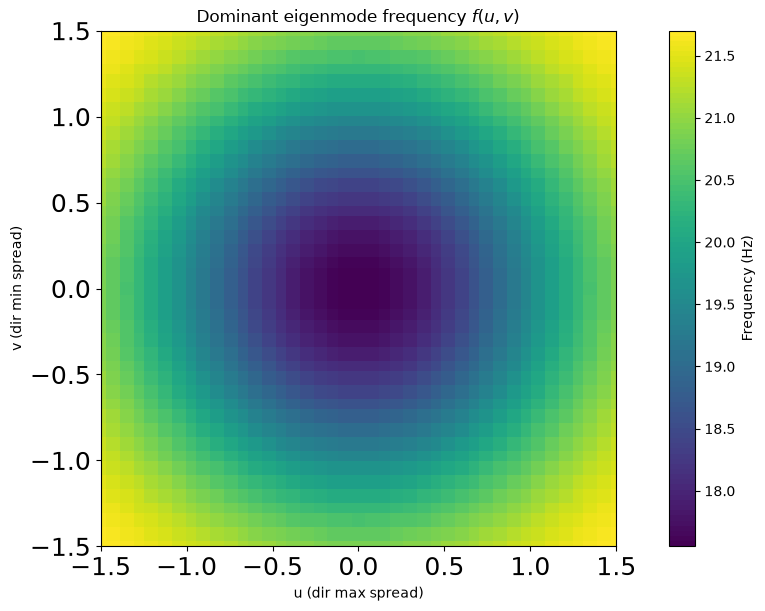

In [10]:

# ------------------------------------------------------------
# Same quantity expressed as frequency in Hz
# ------------------------------------------------------------

fig_frequency, ax_frequency = plot_surface(
    Frequency_q,
    r"Dominant eigenmode frequency $f(u,v)$",
    "Frequency (Hz)",
    filename=f"dominant_frequency_{tag}.svg"
)
